## Assignment 05: Wi-Fi Basics


<div class="alert alert-light">

  **Name:** Suleman Ali Khan
  
  **Matriculation Number:** 21-715-917
  
</div>



The submission deadline is <span style="background-color:rgba(0, 150, 255, 0.5); padding:2px 4px; border-radius:3px;">Monday, 2026-Oct-26 (23:59)</span>.
Students <span style="background-color:rgba(255, 123, 0, 0.5); padding:2px 4px; border-radius:3px;">must work alone</span> and provide their own results. 

Fill in your responses below in the marked blocks. The expected length of each answer is provided in each block.

- (S) Short, 1–2 sentences (~20–40 words). *A quick factual or definition-style answer.*
- (M) Medium, 3–8 sentences (~60–120 words). *Brief explanation with reasoning or an example.*
- (L) Long, multi-paragraph (150–300 words). *Detailed discussion, include reasoning, examples, and context.*
- (V) Visualizations and graphs. *Include plots or figures that illustrate your results.*
- (E) Statistical evaluation and information. *Provide numeric context such as mean, variance, random seed used, confidence intervals, etc.*

Save this notebook and upload the modified file to Moodle.

The motivation for this assignment is to understand what each frame exchange costs in IEEE 802.11, what RTS/CTS adds to it, and how MAC parameters change performance when two stations share the medium.

---

## Questions



### Step 1: MAC Protocol and Parameters (2 points)

1) What is the function of RTS/CTS in the MAC protocol?

<div class="alert alert-info">

(S) Answer: RTS/CTS reserves the channel before data transmission: the sender requests access, the receiver grants it, and nearby stations defer for the announced duration. This reduces hidden-terminal collisions, especially for long frames, but adds control-frame overhead.

2) What is the difference between a positive and negative acknowledgement, and why does 802.11 mainly use positive acknowledgements?

<div class="alert alert-info">

(M) Answer: A positive acknowledgement (ACK) confirms that a frame was received correctly; a negative acknowledgement (NACK) reports that it was lost or corrupted. 802.11 mainly uses ACKs because a missing ACK signals a likely transmission failure, prompting the sender to retry, while avoiding extra NACK traffic and potential collisions on the shared wireless channel.

3) What is the difference between DCF and PCF in 802.11?

<div class="alert alert-info">

(S) Answer: DCF (Distributed Coordination Function) is the mandatory, contention-based access method: stations compete for the channel using carrier sensing and random backoff. PCF (Point Coordination Function) is an optional, contention-free method in which an access point polls stations in turn, providing more predictable access.



4) Discuss the following parameters of the IEEE 802.11 Management Information Base (MIB): `dot11FragmentationThreshold`, `dot11LongRetryLimit`, `dot11RTSThreshold`, `dot11ShortRetryLimit`. What is the functionality and purpose of each? They are defined in the `dot11OperationTable` in Annex D of [IEEE Std 802.11, 1999 Edition](https://www.csd.uoc.gr/~hy439/reading/802.11-1999.pdf#page=498), printed pages 483-484 (pages 498-499 of the PDF).

<div class="alert alert-info">

(L) Answer:

dot11FragmentationThreshold sets the maximum frame size allowed before the MAC fragments a packet into smaller frames. Fragmentation can reduce the cost of retransmitting data when errors occur, since only a failed fragment needs to be resent, but it adds headers and acknowledgements and therefore increases overhead.

dot11LongRetryLimit sets the maximum number of transmission attempts for a frame longer than dot11RTSThreshold. dot11ShortRetryLimit sets the corresponding limit for a frame at or below that threshold. If a frame still cannot be delivered after its applicable limit, the MAC gives up and reports a transmission failure. Separate limits let the station handle longer and shorter frames differently.

dot11RTSThreshold determines when the MAC uses the RTS/CTS exchange before sending a frame: frames longer than the threshold use RTS/CTS, while shorter ones are sent without it. This can reduce collisions from hidden stations, especially for long frames, but the extra control frames consume airtime. In short, the fragmentation and RTS thresholds control how frames are sent; the retry limits control how persistently failed transmissions are retried.



5) The .xml configuration below is an excerpt of a Jemula scenario. Explain how the values of `dot11FragmentationThreshold`, `dot11RTSThreshold`, `dot11ShortRetryLimit` and `dot11LongRetryLimit` affect the behavior of the 802.11 protocol, and what changes if you adjust them.

   ```xml
   <MIB802.11-1999 dot11BroadcastAddress="255"
      dot11FragmentationThreshold="512" dot11LongRetryLimit="4"
      dot11MACAddress="2" dot11MaxReceiveLifetime="1000"
   dot11MaxTransmitMSDULifetime="1000" dot11RTSThreshold="500"
   dot11ShortRetryLimit="7" />
   ```

<div class="alert alert-info">

(L) Answer:

The fragmentation threshold (512 bytes) determines when a data packet is split into smaller MAC frames. If a packet exceeds this limit, it is fragmented; this can reduce the amount of data that must be retransmitted after an error, but adds per-fragment headers, acknowledgements, and airtime. Raising the threshold means fewer larger frames; lowering it means more smaller fragments and more overhead.

The RTS threshold (500 bytes) determines when a station uses the Request-to-Send/Clear-to-Send exchange before transmitting. Frames larger than the threshold use RTS/CTS, which can help prevent collisions from hidden stations but adds control-frame overhead. Lowering the threshold uses RTS/CTS more often; raising it uses it less often.

The short retry limit (7) and long retry limit (4) set how many retries the MAC allows after unsuccessful transmissions. The short limit applies to frames at or below the RTS threshold; the long limit applies to frames above it. If the applicable limit is reached without success, the MAC abandons the transmission. Increasing a limit can improve delivery under interference, but may increase delay and consume more airtime; decreasing it gives up sooner. In this configuration, the two thresholds determine frame handling, while the retry limits determine how persistent the station is when transmissions fail.

10


### Step 2: Single Sender (3 points)

1) Open [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb). Input the scenario `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_MAC_Saturation_120byte.xml"` and enter your legi number. Run it to get a baseline result. What is happening with the offered traffic in this scenario?

<div class="alert alert-info">

(S) Answer: After startup, the offered traffic rises to about 27 Mb/s, while throughput levels off near 2.5 Mb/s. The sender is offering packets faster than the wireless channel can deliver them, so the network is saturated and packet delay increases. 

2) Open [`Jemula802_Results.ipynb`](../../notebooks/01%20Jemula/Jemula802_Results.ipynb). Input the same scenario and use the total logged outputs. Provide the simulation result plot and the PDF / CCDF plot.

<div class="alert alert-info">

(V) Answer: 

![2.2 - Simulation Result.png](<attachment:2.2 - Simulation Result.png>)
![2.2 - PDF, CCDF.png](<attachment:2.2 - PDF, CCDF.png>)
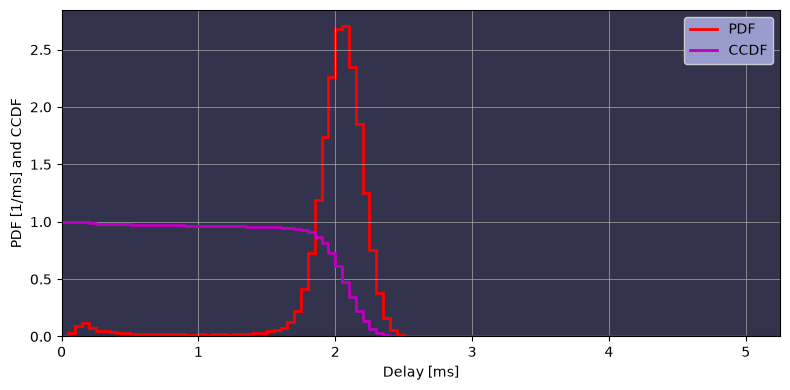
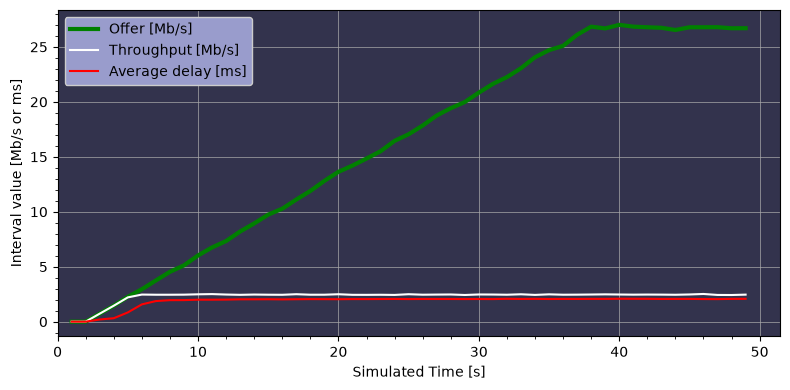

3) Change the scenario to `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_MAC_Saturation_1000byte.xml"`. What has changed compared to the initial `.xml` file? Run the new scenario.

<div class="alert alert-info">

(S) Answer: The max_packet_size_byte is changed from being 120 to 1000 bytes

4) Provide the simulation result plot and the PDF / CCDF plot for this scenario. Why is the throughput higher than with 120 bytes?

<div class="alert alert-info">

(V, S) Answer: 

![2.4 - Simulation Result.png](<attachment:2.4 - Simulation Result.png>)
![2.4 - PDF, CCDF.png](<attachment:2.4 - PDF, CCDF.png>)

Larger packets carry more useful data per transmission, so fixed overhead takes a smaller share of airtime and throughput increases.



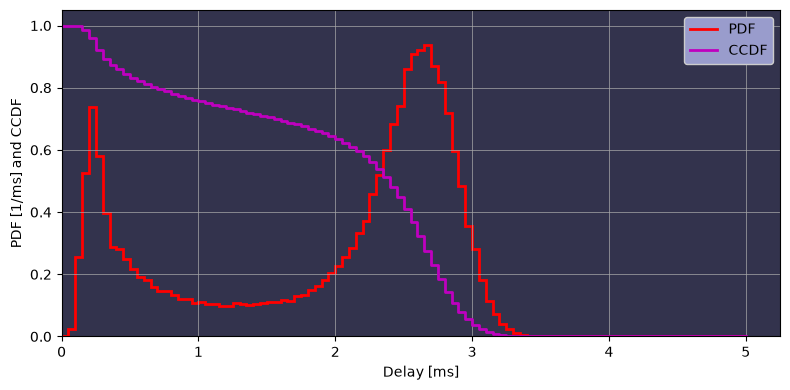
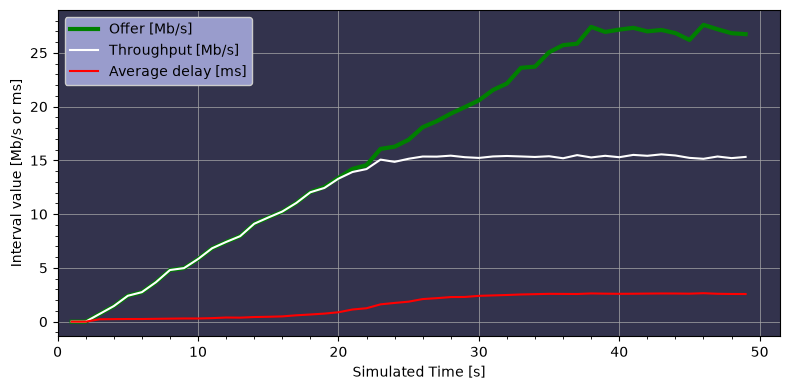

5) Make a copy of both scenarios, set `dot11RTSThreshold="0"` for all stations and change `Path2Results` to a new folder. What does this change? Run both.

<div class="alert alert-info">

(S) Answer: Setting the RTS threshold to 0 enables RTS/CTS for every packet.




6) Upload both new `.xml` files. Did you include these files separately in your submission?

<div class="alert alert-info">

(S) Answer: Both files can be found in `Additional_Files.zip` as `WNMC_MAC_Saturation_120byte_0_threshold.xml` and `WNMC_MAC_Saturation_1000byte_0_threshold.xml`

7) Provide the simulation result plots for both new runs.

<div class="alert alert-info">

(V) Answer: 

**120 Byte Packets**

![2.7 - 120 Byte Simulation Result.png](<attachment:2.7 - 120 Byte Simulation Result.png>)

**1000 Byte Packets**

![2.7 - 1000 Byte Simulation Result.png](<attachment:2.7 - 1000 Byte Simulation Result.png>)
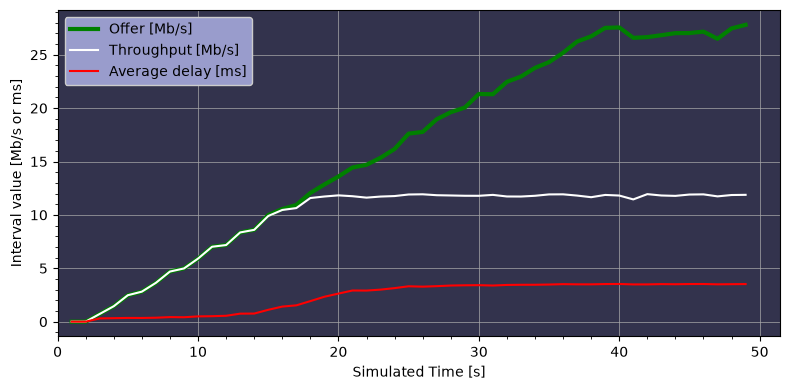
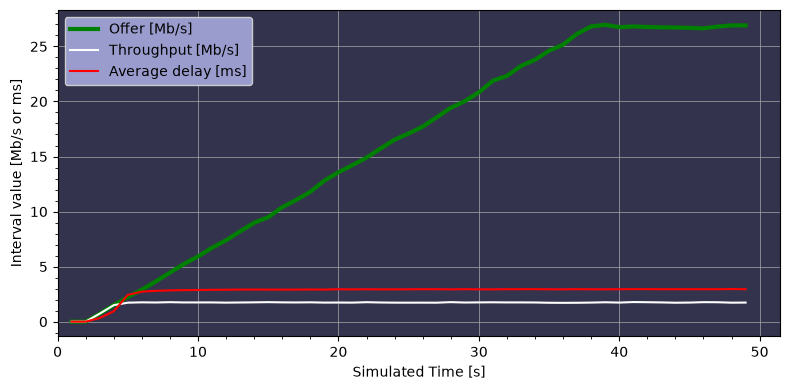

8) What is the saturation throughput (the average throughput once the curve is flat) in each of your four runs? Use [`Scientific_Confidence.ipynb`](../../notebooks/00%20Scientific/Scientific_Confidence.ipynb) to get statistical confidence. The notebook uses all rows of a CSV, so adapt it to use only the values of the flat part, and state the time interval you used. For which packet size is the relative cost of RTS/CTS higher, and why?

<div class="alert alert-info">

(S, E) Answer:

I used the last-interval throughput measurements from 30–49 s (20 samples per run). The mean saturation throughputs and 95% t-confidence intervals are:

Dataset: MAC_Saturation_120byte/total_thrp
 - Column:  thrp last interval [Mb/s]
 - n:       20
 - Mean:    2.46352 Mb/s
 - StdDev:  0.0218346 Mb/s
 - SE:      0.00488236 Mb/s
 - 95% t CI: [2.45331, 2.47374] Mb/s

Dataset: MAC_Saturation_1000byte/total_thrp
 - Column:  thrp last interval [Mb/s]
 - n:       20
 - Mean:    15.3446 Mb/s
 - StdDev:  0.112478 Mb/s
 - SE:      0.0251508 Mb/s
 - 95% t CI: [15.292, 15.3973] Mb/s

Dataset: MAC_Saturation_120byte_0_threshold/total_thrp
 - Column:  thrp last interval [Mb/s]
 - n:       20
 - Mean:    1.74232 Mb/s
 - StdDev:  0.0199812 Mb/s
 - SE:      0.00446794 Mb/s
 - 95% t CI: [1.73297, 1.75168] Mb/s

Dataset: MAC_Saturation_1000byte_0_threshold/total_thrp
 - Column:  thrp last interval [Mb/s]
 - n:       20
 - Mean:    11.809 Mb/s
 - StdDev:  0.115901 Mb/s
 - SE:      0.0259163 Mb/s
 - 95% t CI: [11.7547, 11.8632] Mb/s

RTS/CTS reduces throughput by about **29.3%** for 120-byte packets and **23.0%** for 1000-byte packets. Its relative cost is higher for smaller packets because the RTS/CTS exchange adds fixed airtime overhead while protecting less payload data.

### Step 3: Two Senders (3 points)

1) Open [`Jemula802_Run.ipynb`](../../notebooks/01%20Jemula/Jemula802_Run.ipynb). Input the scenario `"./jemula-project/my-simulations/scenarios/ETH_Course/WNMC_MAC_TwoSenders.xml"` and enter your legi number. What has changed compared to the scenarios in Step 2? Set `showGui="true"` and run it.

<div class="alert alert-info">

(S) Answer: Unlike Step 2, this scenario has two senders (Stations 2 and 3) transmitting to Station 1, so they compete for the shared wireless channel.

2) Open [`Jemula802_Results.ipynb`](../../notebooks/01%20Jemula/Jemula802_Results.ipynb) and provide the simulation result plot. Analyze and interpret the results. Support your findings with GUI snapshots from the simulation (screenshots of the run's packet timeline in `timeline.html`).

<div class="alert alert-info">

(V, L) Answer: 

![3.2 - Simulation Result.png](<attachment:3.2 - Simulation Result.png>)

![2.2 - Simulation Result Jemula.png](<attachment:2.2 - Simulation Result Jemula.png>)


After the startup period, total throughput stabilizes around **4.15 Mb/s**, with each sender contributing about **2.06 Mb/s**. The senders therefore share the channel approximately equally. Offered traffic and delivered throughput are close, and average delay remains around **5.8 ms**, with only small fluctuations.

**Packet timeline**

![3.2 - Packet Timeline.png](<attachment:3.2 - Packet Timeline.png>)

The timeline shows Stations 2 and 3 sending to Station 1. Their transmissions take turns accessing the shared channel, illustrating contention and channel sharing.

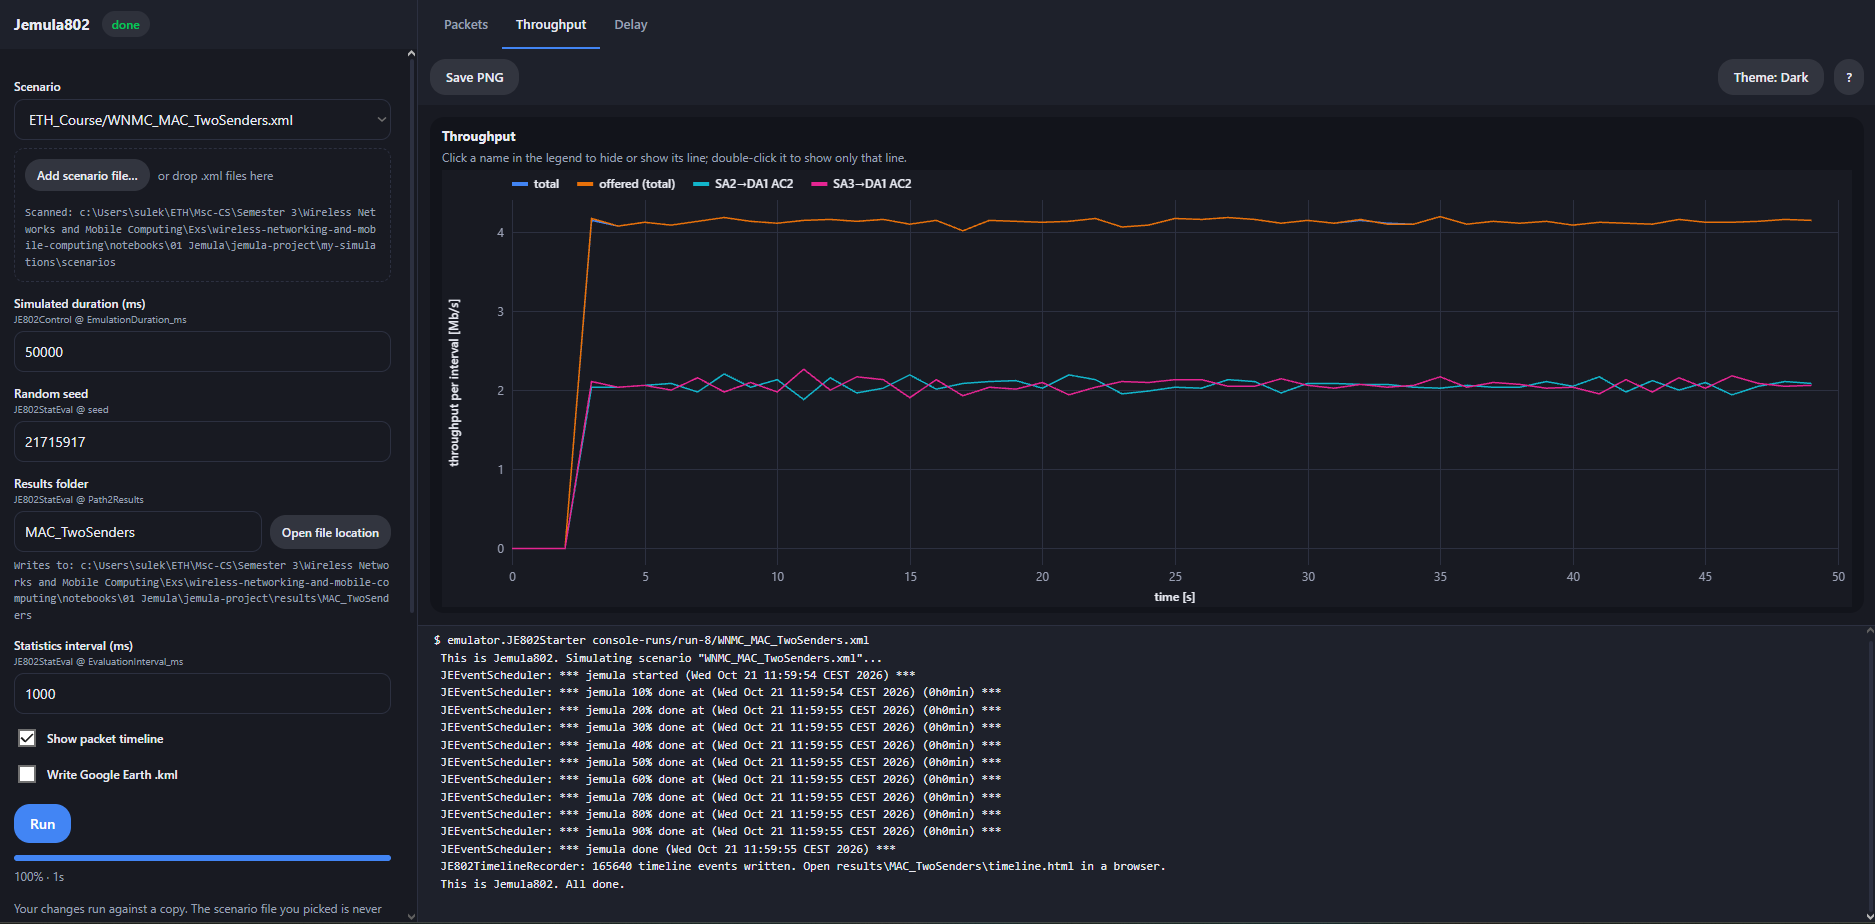
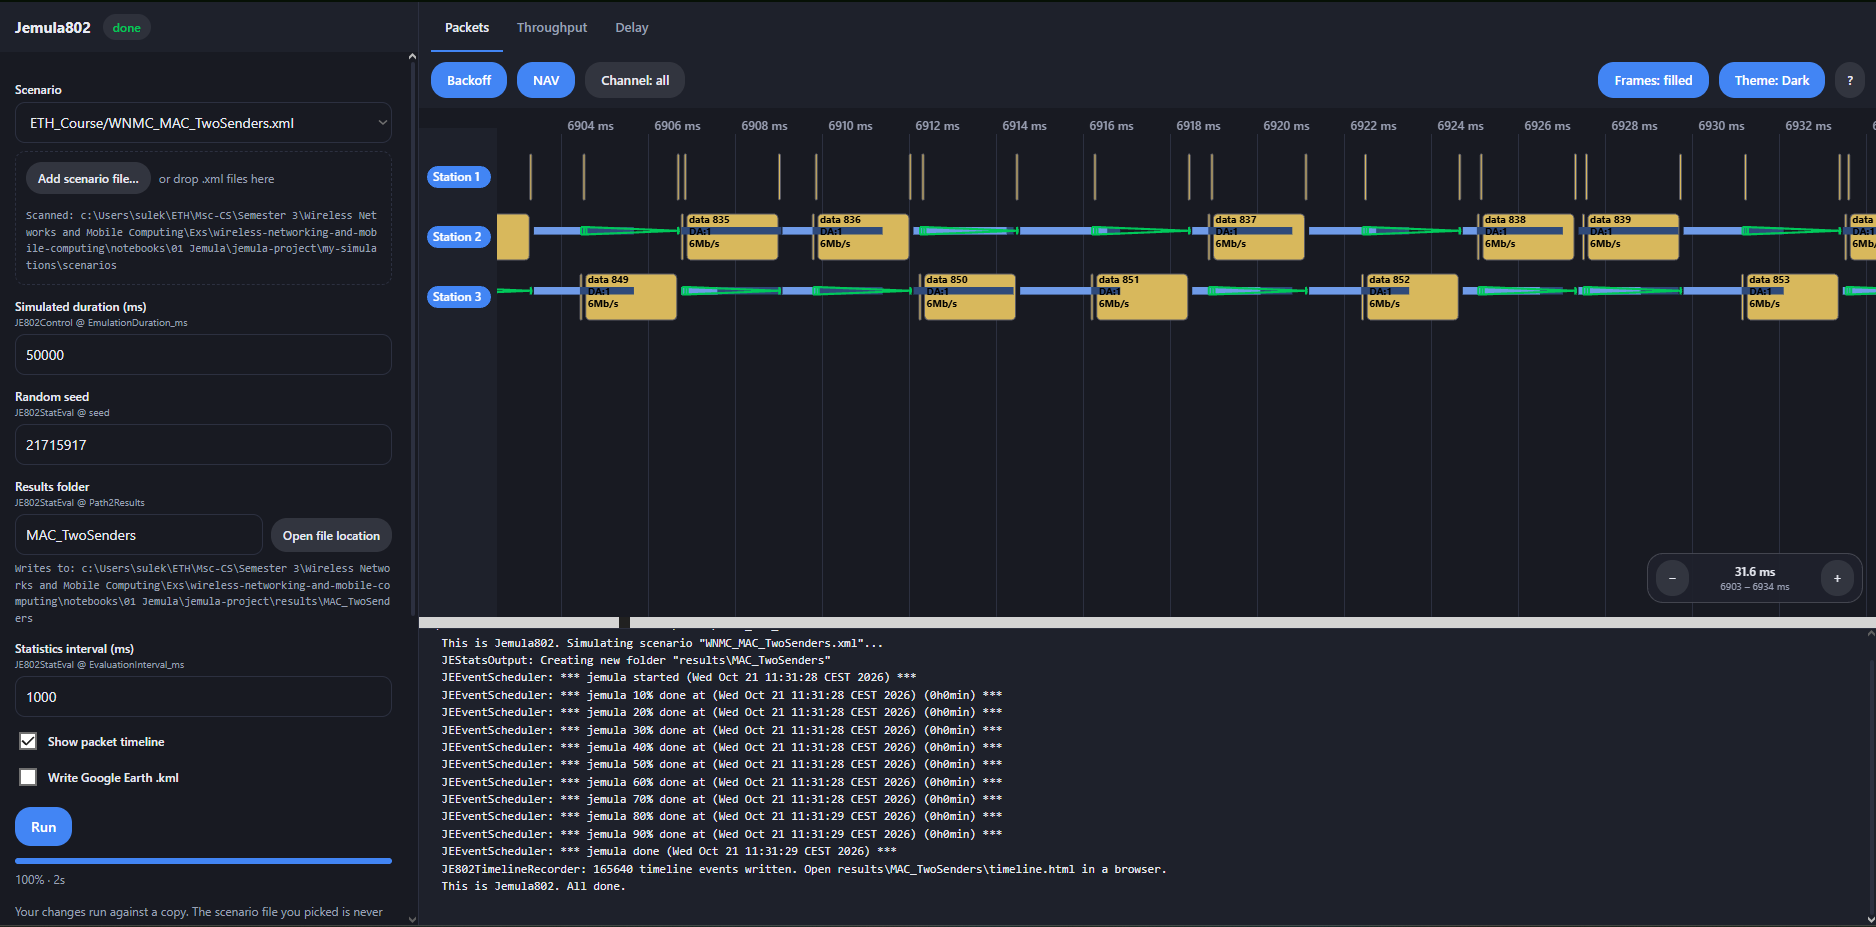
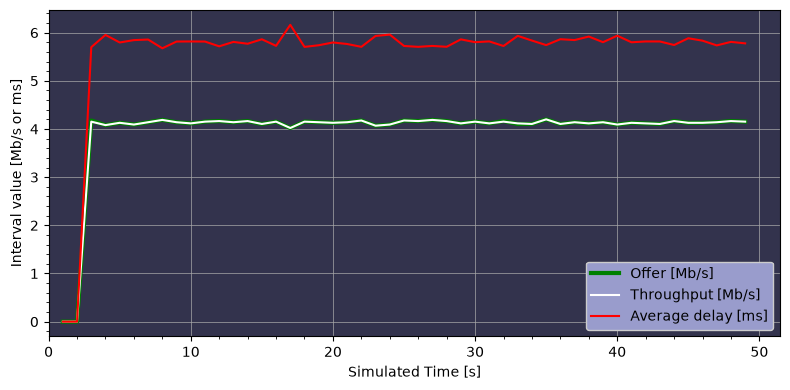

3) When is RTS/CTS useful, and when is it not?

<div class="alert alert-info">

(M) Answer: RTS/CTS is useful with hidden nodes or long data frames, where it can prevent costly collisions. It is less useful for short packets or lightly loaded networks, because the extra RTS/CTS exchange adds overhead and can reduce throughput.



4) Make a copy of the scenario and change `Path2Results` to a new folder. Change `dot11RTSThreshold`, `dot11EDCAAIFSN` and `dot11EDCACWmin` to reach the highest total throughput you can. Provide the simulation result plot. Which values did you choose, and why? How much did the average throughput improve compared to the initial scenario? Use [`Scientific_Confidence.ipynb`](../../notebooks/00%20Scientific/Scientific_Confidence.ipynb) to get statistical confidence, adapted to leave out the first seconds before both stations send, and state the time interval you used.

<div class="alert alert-info">

(V, E, M) Answer: 

![3.4 - Simulation Result.png](<attachment:3.4 - Simulation Result.png>)

![3.4 - Simulation Result Jemula.png](<attachment:3.4 - Simulation Result Jemula.png>)

I set `dot11RTSThreshold` to 1600 bytes, above the 1500-byte packet size, so RTS/CTS is not used for these packets. The timeline suggests the two senders can hear one another, so RTS/CTS would add overhead without providing much benefit in this scenario.

I set `dot11EDCAAIFSN` to 2, the minimum allowed value. Since both stations have equal priority, they should use the same AIFSN; a larger value would add unnecessary waiting time.

I set `dot11EDCACWmin` to 50 because only two stations contend, so a relatively small contention window should keep collision probability low while reducing backoff.

Using the last-interval throughput measurements from 3–49 s (47 samples per run), the mean total throughput and 95% t-confidence intervals were:


Dataset: MAC_TwoSenders_Improved/total_thrp
 - Column:  thrp last interval [Mb/s]
 - n:       47
 - Mean:    4.13387 Mb/s
 - StdDev:  0.0339293 Mb/s
 - SE:      0.0049491 Mb/s
 - 95% t CI: [4.12391, 4.14383] Mb/s

Dataset: MAC_TwoSenders_Improved/total_thrp
 - Column:  thrp last interval [Mb/s]
 - n:       47
 - Mean:    5.1406 Mb/s
 - StdDev:  0.0423565 Mb/s
 - SE:      0.00617833 Mb/s
 - 95% t CI: [5.12816, 5.15303] Mb/s

The average throughput increased by approximately **1.007 Mb/s (24.4%)**.
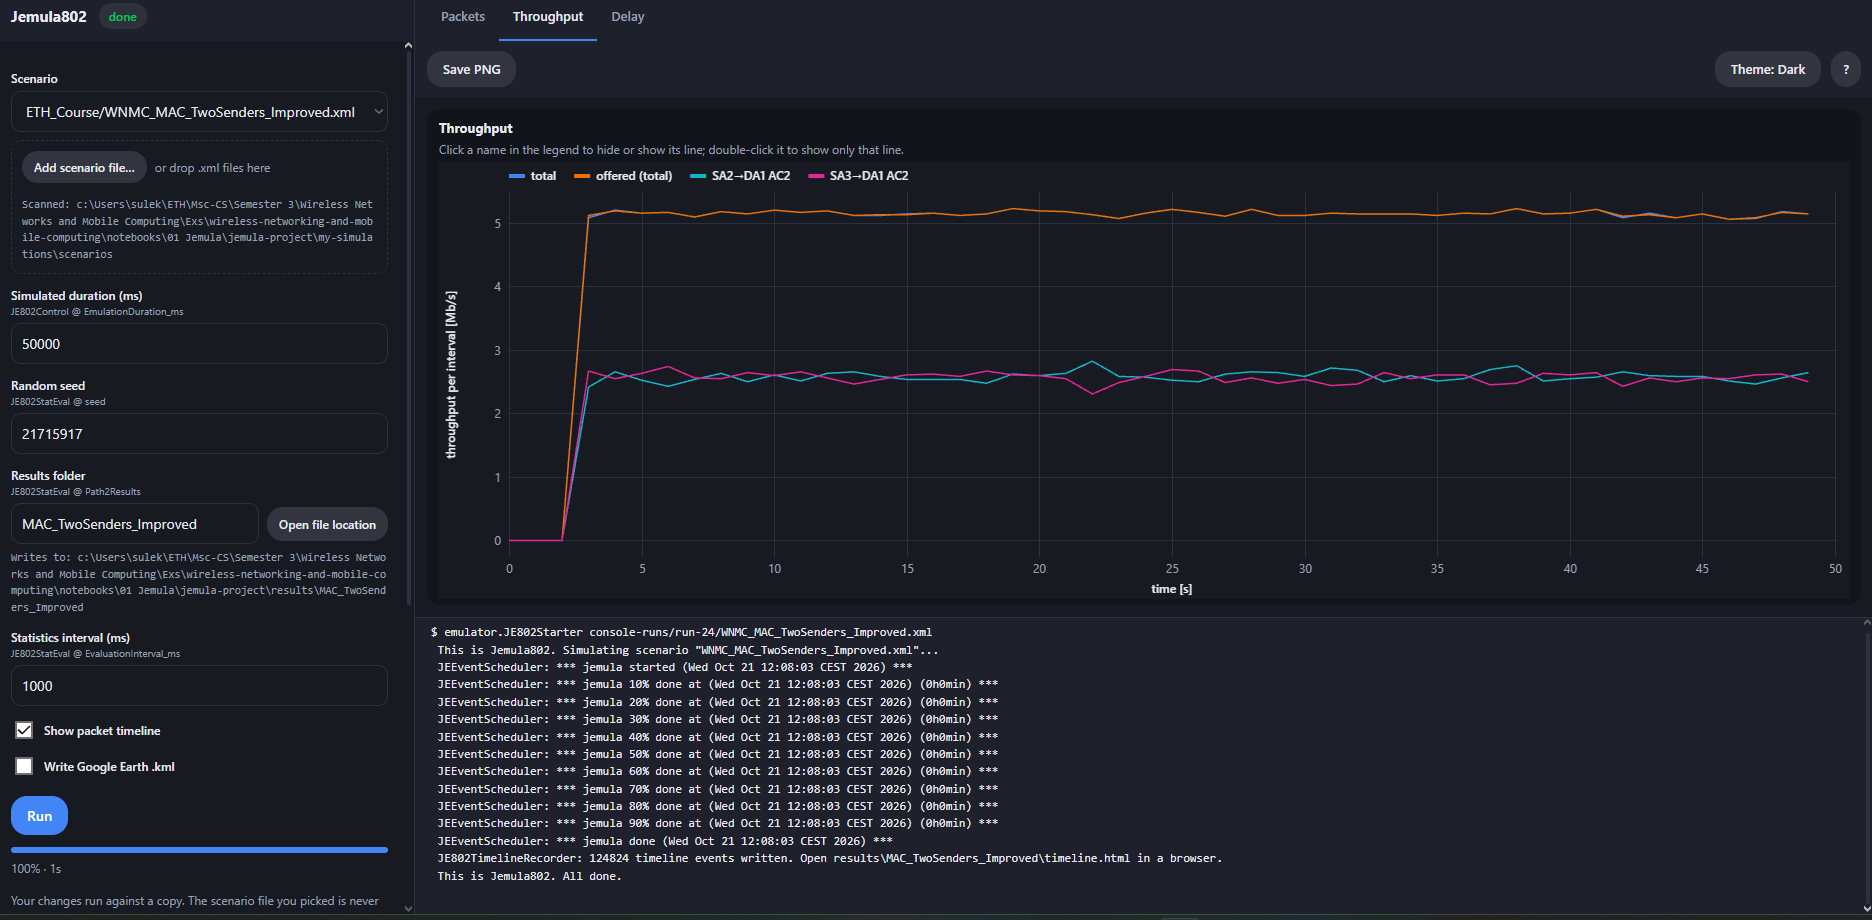
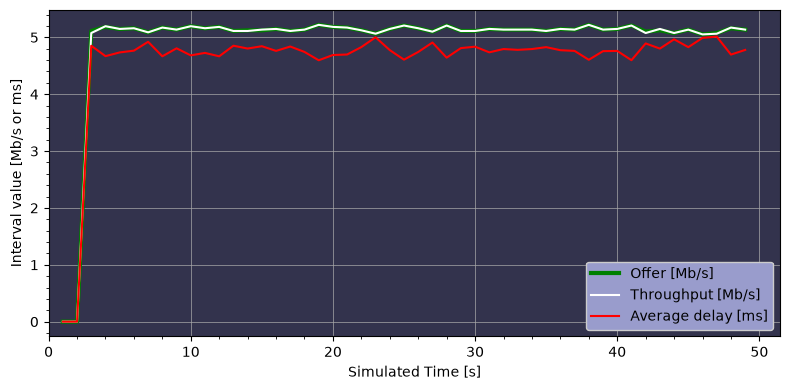

5) Upload your `.xml` file and the logged `total_thrp.csv` by naming it `best_total_thrp.csv`. Did you include these files separately in your submission?

<div class="alert alert-info">

(S) Answer: Both files can be found in `Additional_Files.zip` as `WNMC_MAC_TwoSenders_Improved.xml` and `best_total_thrp.csv`

6) Would your settings still work well with many more stations? What would you change to optimize for low delay instead of high throughput?

<div class="alert alert-info">

(M) Answer: 

With many stations, I would increase `dot11EDCACWmin` to reduce collisions, and enable RTS/CTS if hidden stations are present. I would keep `dot11EDCAAIFSN` equal for stations with equal priority, adjusting it only when prioritizing specific traffic. To reduce delay, I would try a smaller contention window, but not make it too small: excessive collisions and retransmissions can increase delay overall.





### Optional Feedback (not graded)

1. Did you read through and understand all the tasks in this assignment and the related notebooks? Are there any shortcomings, missing parts, or sections that should be improved? You can also give your feedback anonymously, through moodle. Please help the teaching team by telling us what part was not understood, and we will work on it in the future.

<div class="alert alert-info">

Optional Feedback, not graded: *(double click to edit)*